## Day 2: Lines

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import numpy as np
from shapely.geometry import LineString
from matplotlib.colors import Normalize

## Processing

In [2]:
#load data
msoa = pd.read_csv("medianpricepaidformsoa.csv")
lookup = pd.read_csv("MSOA_(2021)_to_Built-up_Area_to_Local_Authority_District_to_Region_(December_2022)_Lookup_in_England_and_Wales_v2.csv")

#combine
df = pd.merge(msoa, lookup[["MSOA21CD", "RGN22CD", "RGN22NM"]], left_on="MSOA code", right_on="MSOA21CD", how="left")

#filter for London
df = df[df["RGN22NM"]=="London"]

#price change since 2016
cols = ["Year ending Mar 2026", "Year ending Mar 2016", "Year ending Dec 2025", "Year ending Dec 2015"]
df[cols] = (
    df[cols]
    .replace(",", "", regex=True)
    .apply(pd.to_numeric, errors="raise")
)
df["2016_perc"] = (df[cols[0]] - df[cols[1]]) / df[cols[1]] * 100
df["2015_perc"] = (df[cols[2]] - df[cols[3]]) / df[cols[3]] * 100

#binary above/below 0
df["2016_bin"] = [1 if i > 0 else 0 for i in df["2016_perc"]]
df["2015_bin"] = [1 if i > 0 else 0 for i in df["2015_perc"]]

In [ ]:
# RUN ONCE

#load geo data
geo = gpd.read_file("Middle_layer_Super_Output_Areas_December_2021_Boundaries_EW_BFC_V7_4217240408829684364.geojson")

#combine with lookup
gdf = pd.merge(geo, lookup[["MSOA21CD", "RGN22NM"]], on="MSOA21CD", how="left")

#filter for London
gdf = gdf[gdf["RGN22NM"]=="London"]

#save filtered file
gdf.to_file("msoa-london.geojson", driver='GeoJSON')

In [3]:
#load filtered msoa
gdf = gpd.read_file("msoa-london.geojson")

#add price change to gdf
gdf = pd.merge(gdf, df[["MSOA code", "2016_perc", "2016_bin", "2015_perc", "2015_bin"]], 
left_on="MSOA21CD", right_on="MSOA code", how="left")

#calculate centroids and project to British National Grid
gdf = gdf.to_crs("EPSG:27700") 
gdf["centroid"] = gdf.geometry.centroid

In [4]:
#summaries
print(gdf["2015_bin"].value_counts())
print(gdf["2015_perc"].describe())

2015_bin
1    907
0     95
Name: count, dtype: int64
count    1002.000000
mean       30.054286
std        21.951156
min       -30.631970
25%        15.244421
50%        31.063604
75%        45.524595
max       108.888889
Name: 2015_perc, dtype: float64


## Visualisation

In [5]:
from pyfonts import load_google_font
import matplotlib.pyplot as plt
from matplotlib import font_manager
#font_manager.findSystemFonts(fontpaths=None, fontext='ttf')

#font_r = load_google_font("Open Sans", weight="regular" )
font_r = font_manager.FontProperties(fname= 'C:\\Windows\\Fonts\\OpenSans-Regular.ttf')
font_b = load_google_font("Open Sans", weight="bold" )
title_font = font_manager.FontProperties(fname= 'C:\\Users\\lisa.hornung\\AppData\\Local\\Microsoft\\Windows\\Fonts\\Graphik-Extralight-Trial.otf')

In [6]:
# Calculate lines to plot
# angle based on value
# length based on value

# drop rows with missing values or empty geometries (empty centroids raise IndexError on .x)
gdf = gdf.dropna(subset=["2015_perc", "geometry"])
gdf = gdf[~gdf.geometry.is_empty & ~gdf["centroid"].is_empty & gdf["centroid"].notna()]
gdf = gdf.reset_index(drop=True)
print(len(gdf), "areas with valid data")

scale_m = 100  # metres per percentage point
lines = []
max_value = gdf["2015_perc"].max()
min_value = gdf["2015_perc"].min()

for centroid, length_value, angle_value in zip(
    gdf["centroid"], gdf["2015_perc"], gdf["2015_perc"]
):
    angle_deg = np.clip(float(angle_value), -max_value, max_value) * (65 / max_value)
    angle = np.deg2rad(angle_deg)

    length = abs(float(length_value)) * scale_m * 0.7
    end_x = centroid.x + length * np.cos(angle)
    end_y = centroid.y + length * np.sin(angle)

    lines.append(LineString([(centroid.x, centroid.y), (end_x, end_y)]))

line_series = gpd.GeoSeries(lines, index=gdf.index, crs=gdf.crs)

line_gdf = gpd.GeoDataFrame(
    {"2015_perc": gdf["2015_perc"], "geometry": line_series},
    crs=gdf.crs,
)

1001 areas with valid data


C:\Users\lisa.hornung\AppData\Local\Temp\ipykernel_17936\2455475909.py:7: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since the calling GeoSeries contains empty geometries, the result has changed compared to previous versions of GeoPandas.
Given a GeoSeries 's', you can use '~s.is_empty & s.notna()' to get back the old behaviour.

To further ignore this warning, you can do: 
import warnings; warnings.filterwarnings('ignore', 'GeoSeries.notna', UserWarning)
  gdf = gdf[~gdf.geometry.is_empty & ~gdf["centroid"].is_empty & gdf["centroid"].notna()]


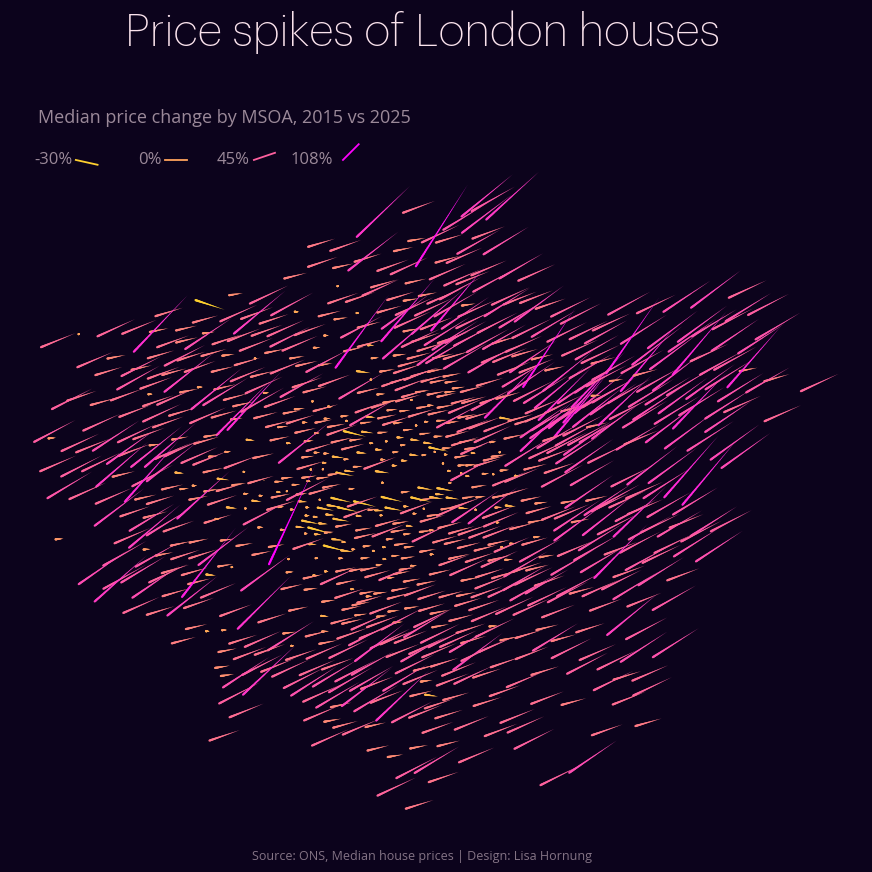

In [8]:
fig, ax = plt.subplots(figsize=(11, 11))
cmap = plt.get_cmap("spring_r")
fig.set_facecolor("#0C031C")

from matplotlib.collections import LineCollection

segments = []
widths = []
segment_colors = []

n_segments = 40
color_norm = plt.Normalize(vmin=min_value *2, vmax=max_value)
colors = [cmap(color_norm(value)) for value in line_gdf["2015_perc"]]

for line, color in zip(line_gdf.geometry, colors):
    (x0, y0), (x1, y1) = line.coords[:2]

    points = np.column_stack((
        np.linspace(x0, x1, n_segments + 1),
        np.linspace(y0, y1, n_segments + 1),
    ))

    for i in range(n_segments):
        segments.append([points[i], points[i + 1]])
        widths.append(np.interp(i, [0, n_segments - 1], [1.6, 0.03]))
        segment_colors.append(color)

hair_lines = LineCollection(
    segments,
    colors=segment_colors,
    linewidths=widths,
    capstyle="round",
    zorder=3,
)
ax.add_collection(hair_lines)

# Zoom the axes to the British National Grid line coordinates
minx, miny, maxx, maxy = line_gdf.total_bounds
x_pad = (maxx - minx) * 0.03
y_pad = (maxy - miny) * 0.03

ax.set_xlim(minx - x_pad, maxx + x_pad)
ax.set_ylim(miny - y_pad, maxy + y_pad)
ax.set_aspect("equal")
ax.axis("off")

# inset axes for legend at the bottom left
legend_ax = ax.inset_axes([-0.04, .88, 0.6, 0.22])
legend_ax.set_axis_off()

legend_values = [-30,0,  45, 108]
legend_line_length = 0.15

legend_ax.set_xlim(0, 2.2)
legend_ax.set_ylim(0, 1)
legend_ax.set_aspect("equal")

for i, value in enumerate(legend_values):
    angle_deg = np.clip(value, - 108,  108) * (45 /  108)
    angle = np.deg2rad(angle_deg)

    x0 = 0.05 + i * 0.6
    y0 = 0.5
    x1 = x0 + legend_line_length * np.cos(angle)
    y1 = y0 + legend_line_length * np.sin(angle)

    legend_ax.plot(
        [x0, x1], [y0, y1],
        color=cmap(color_norm(value)),
        linewidth=1.3,
    )
    legend_ax.text(
        x1 - 0.17, y0 + 0.0, f"{value}%",
        ha="right",
        va="center",
        color="#FBE3ED",
        fontsize=12,
        font=font_r,
        alpha=0.6
    )


#titles
fig.text(0.5,0.9 , "Price spikes of London houses", font_properties=title_font, 
    color="#FBE3ED", fontsize=32, fontweight="bold", ha="center")
fig.text(0.15,0.83 , "Median price change by MSOA, 2015 vs 2025", font_properties=font_r, 
    color="#FBE3ED", fontsize=13, fontweight="bold", ha="left", alpha=0.6)
fig.text(0.5,0.16, "Source: ONS, Median house prices | Design: Lisa Hornung", 
    font_properties=font_r, color="#FBE3ED", ha="center", fontsize=9, alpha=0.5, linespacing=1.7)


#export
#plt.savefig("house-prices.svg")
plt.savefig("house-prices.png", bbox_inches='tight', pad_inches=0.65, dpi=300)

plt.show()


## Playground

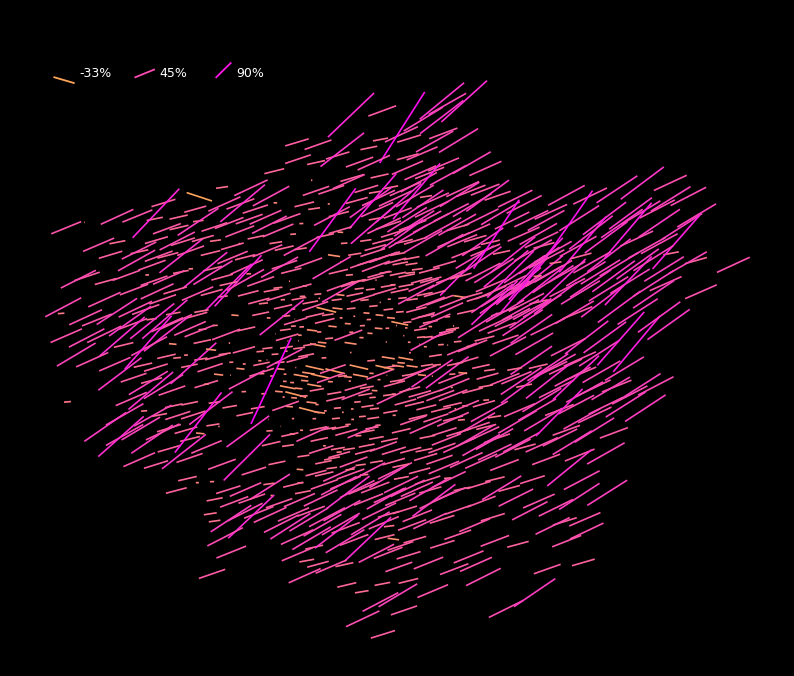

In [14]:
fig, ax = plt.subplots(figsize=(10, 10))
cmap = plt.get_cmap("spring_r")
fig.set_facecolor("black")

line_gdf.plot(
    ax=ax,
    column="2015_perc",
    cmap=cmap,  
    vmin=-max_value,
    vmax=max_value,
    linewidth=1.2,
    legend=False,
)
ax.axis("off")

# inset axes for legend at the bottom left
legend_ax = ax.inset_axes([-0.1, .85, 0.68, 0.22])
legend_ax.set_axis_off()

legend_values = [-33, 45, 90]
legend_line_length = 0.15
color_norm = plt.Normalize(vmin=-max_value, vmax=max_value)

legend_ax.set_xlim(0, 2.2)
legend_ax.set_ylim(0, 1)
legend_ax.set_aspect("equal")

for i, value in enumerate(legend_values):
    angle_deg = np.clip(value, -91, 91) * (45 / 91)
    angle = np.deg2rad(angle_deg)

    x0 = 0.05 + i * 0.6
    y0 = 0.5
    x1 = x0 + legend_line_length * np.cos(angle)
    y1 = y0 + legend_line_length * np.sin(angle)

    legend_ax.plot(
        [x0, x1], [y0, y1],
        color=cmap(color_norm(value)),
        linewidth=1.3,
    )
    legend_ax.text(
        x1 + 0.04, y0 + 0.03, f"{value}%",
        va="center",
        color="white",
        fontsize=9
    )

plt.show()
